In [1]:
from astropy.table import Table
from astropy.io import fits
from astropy.io.fits import BinTableHDU
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [2]:
datasets = {
    "FLA": {
        "filename": "FLAMES-30Dor-6563",
        "label": "FLAMES",
        "multiply_r_by_pix_pc": False,
    },

    "FLA MUSE": {
        "filename": "FLAMES-30Dor-6563-MUSE",
        "label": "FLAMES MUSE",
        "multiply_r_by_pix_pc": False,
    },

    "FLA FP": {
        "filename": "FLAMES-30Dor-6563-SAMFP",
        "label": "FLAMES FP",
        "multiply_r_by_pix_pc": False,
    },

    "LVM MUSE": {
        "filename": "LVM-30Dor-6563-MUSE",
        "label": "LVM MUSE",
        "multiply_r_by_pix_pc": False,
    },

    "LVM FP": {
        "filename": "LVM-30Dor-6563-SAMFP",
        "label": "LVM FP",
        "multiply_r_by_pix_pc": False,
    },
    
    
    "LVM_25": {
        "filename": "LVM-30Dor-6563_25",
        "label": "LVM 25",
        "multiply_r_by_pix_pc": False,
    },

    "LVM_50": {
        "filename": "LVM-30Dor-6563_50",
        "label": "LVM 50",
        "multiply_r_by_pix_pc": False,
    },

    "LVM_100": {
        "filename": "LVM-30Dor-6563_100",
        "label": "LVM 100",
        "multiply_r_by_pix_pc": False,
    },

    "LVM_150": {
        "filename": "LVM-30Dor-6563_150",
        "label": "LVM 150",
        "multiply_r_by_pix_pc": False,
    },

    "LVM_200": {
        "filename": "LVM-30Dor-6563_200",
        "label": "LVM 200",
        "multiply_r_by_pix_pc": False,
    },

    "LVM_250": {
        "filename": "LVM-30Dor-6563_subrot-01",
        "label": "LVM 250",
        "multiply_r_by_pix_pc": False,
    },

    "MUSE": {
        "filename": "MUSE-Dor-H-bin0",
        "label": "MUSE",
        "multiply_r_by_pix_pc": True,
    },

    "SAMFP": {
        "filename": "SAMFP-30Dor-Ha-bin0",
        "label": "SAMFP",
        "multiply_r_by_pix_pc": True,
    },
}

In [3]:
datasets.items()

dict_items([('FLA', {'filename': 'FLAMES-30Dor-6563', 'label': 'FLAMES', 'multiply_r_by_pix_pc': False}), ('FLA MUSE', {'filename': 'FLAMES-30Dor-6563-MUSE', 'label': 'FLAMES MUSE', 'multiply_r_by_pix_pc': False}), ('FLA FP', {'filename': 'FLAMES-30Dor-6563-SAMFP', 'label': 'FLAMES FP', 'multiply_r_by_pix_pc': False}), ('LVM MUSE', {'filename': 'LVM-30Dor-6563-MUSE', 'label': 'LVM MUSE', 'multiply_r_by_pix_pc': False}), ('LVM FP', {'filename': 'LVM-30Dor-6563-SAMFP', 'label': 'LVM FP', 'multiply_r_by_pix_pc': False}), ('LVM_25', {'filename': 'LVM-30Dor-6563_25', 'label': 'LVM 25', 'multiply_r_by_pix_pc': False}), ('LVM_50', {'filename': 'LVM-30Dor-6563_50', 'label': 'LVM 50', 'multiply_r_by_pix_pc': False}), ('LVM_100', {'filename': 'LVM-30Dor-6563_100', 'label': 'LVM 100', 'multiply_r_by_pix_pc': False}), ('LVM_150', {'filename': 'LVM-30Dor-6563_150', 'label': 'LVM 150', 'multiply_r_by_pix_pc': False}), ('LVM_200', {'filename': 'LVM-30Dor-6563_200', 'label': 'LVM 200', 'multiply_r_by_

# Load data

In [4]:
def load_structure_function_dataset(info):
    """
    Load one FITS file containing structure-function data.

    This version:
    - reads the structure-function table from HDU='TABLE'
    - reads MOM0, MOM1, MOM2, MASK if they exist
    - reads HDU 1 as a table if HDU 1 is a BinTableHDU
    - stores everything inside the dataset dictionary
    """

    filename = info["filename"] + ".fits"

    with fits.open(filename) as hdul:

        # Copy primary header
        hdr = hdul[0].header.copy()

        # Get list of HDU names
        hdu_names = [hdu.name for hdu in hdul]

        # Store HDU names for later inspection
        info["hdu_names"] = hdu_names

        # -------------------------------------------------
        # Read HDU 1 only if it is a table
        # -------------------------------------------------
        if len(hdul) > 1 and isinstance(hdul[1], BinTableHDU):

            data_hdu1 = Table(hdul[1].data)
            frame_hdu1 = data_hdu1.to_pandas()

            info["data_hdu1"] = data_hdu1
            info["frame_hdu1"] = frame_hdu1
            info["hdu1_name"] = hdul[1].name

        # -------------------------------------------------
        # Read image HDUs if they exist
        # -------------------------------------------------
        if "MOM0" in hdu_names:
            info["mom0"] = hdul["MOM0"].data.copy()

        if "MOM1" in hdu_names:
            info["mom1"] = hdul["MOM1"].data.copy()

        if "MOM2" in hdu_names:
            info["mom2"] = hdul["MOM2"].data.copy()

        if "MASK" in hdu_names:
            info["mask_image"] = hdul["MASK"].data.copy()

    # -------------------------------------------------
    # Read structure-function table
    # -------------------------------------------------
    data = Table.read(filename, hdu="TABLE")
    frame = data.to_pandas()

    # Mask valid structure-function bins
    if "N pairs" in frame.columns:
        sf_mask = np.array(frame["N pairs"]) > 0
    else:
        sf_mask = np.ones(len(frame), dtype=bool)

    # Extract B(r)
    B = np.array(frame["Unweighted B(r)"])[sf_mask]

    # Extract r
    r = 10 ** np.array(frame["log10 r"])[sf_mask]

    # Optional physical scaling
    if info.get("multiply_r_by_pix_pc", False):

        required_keys = ["PIX", "PC"]
        missing_keys = [k for k in required_keys if k not in hdr]

        if missing_keys:
            raise KeyError(
                f"{info['filename']} requires PIX and PC scaling, "
                f"but these header keys are missing: {missing_keys}"
            )

        pix = hdr["PIX"]
        pc = hdr["PC"]

        r = r * pix * pc

        info["pix"] = pix
        info["pc"] = pc

    # Optional header values
    if "SIG2" in hdr:
        info["sig2"] = hdr["SIG2"]

    # Store table and processed structure-function arrays
    info["table"] = data
    info["frame"] = frame
    info["header"] = hdr
    info["B"] = B
    info["r"] = r
    info["sf_mask"] = sf_mask

    return info

In [5]:
for key, info in datasets.items():
    datasets[key] = load_structure_function_dataset(info)

# B(r) comparison

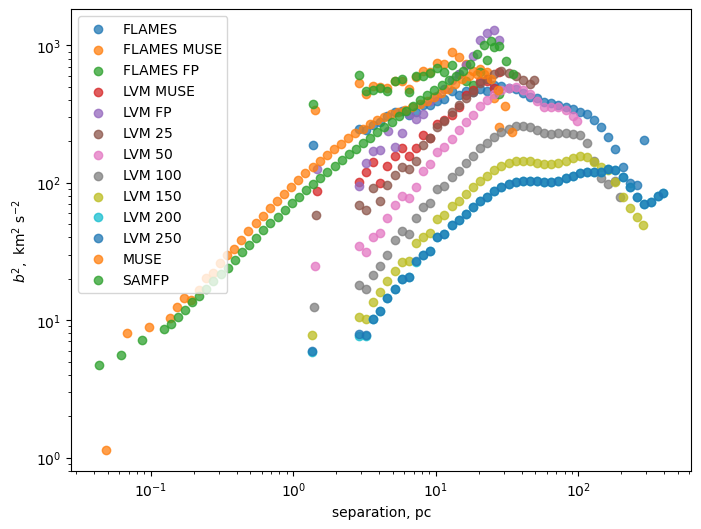

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

for key, info in datasets.items():

    ax.scatter(
        info["r"],
        info["B"],
        label=info["label"],
        alpha=0.75,
    )

ax.legend()

ax.set(
    xscale="log",
    yscale="log",
    xlabel="separation, pc",
    ylabel=r"$b^2,\ \mathrm{km^2\ s^{-2}}$",
)

plt.show()

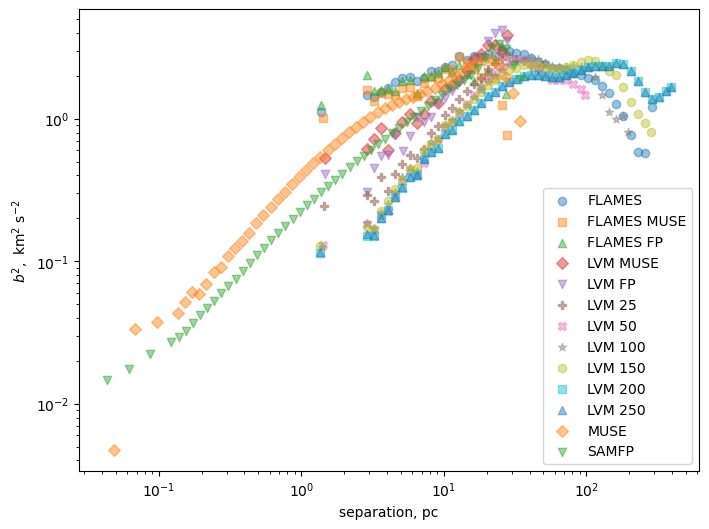

In [7]:
from itertools import cycle
markers = cycle(["o", "s", "^", "D", "v", "P", "X", "*"])

fig, ax = plt.subplots(figsize=(8, 6))

for key, info in datasets.items():

    marker = next(markers)

    ax.scatter(
        info["r"],
        info["B"]/info["sig2"],
        label=info["label"],
        alpha=0.45,
        marker=marker
    )

ax.legend()

ax.set(
    xscale="log",
    yscale="log",
    xlabel="separation, pc",
    ylabel=r"$b^2,\ \mathrm{km^2\ s^{-2}}$",
)

plt.show()

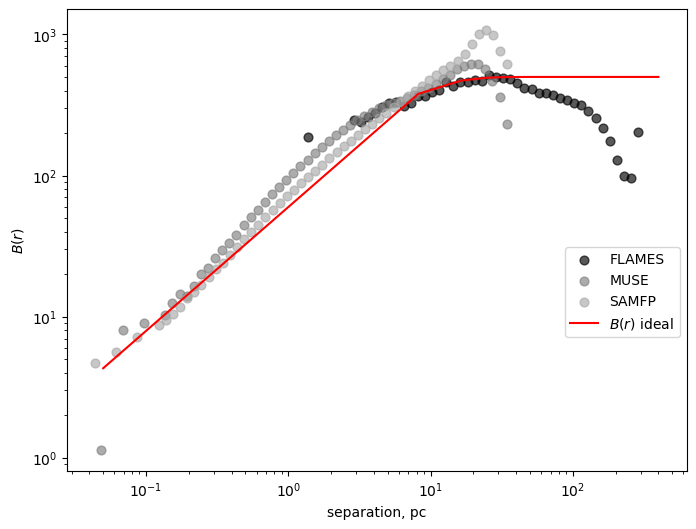

In [8]:
import bfunc

rgrid = np.linspace(0.05, 400)

samples_to_plot = ["FLA", 
                   "MUSE",
#                   "LVM_150",
                   "SAMFP",
 #                  "FLA MUSE", 
 #                  "FLA FP"
                  ]
colors = cycle(["black",
                "gray",
#                "tab:blue",
                'darkgray',
#                'dimgray',
#                'silver'
               ])


fig, ax = plt.subplots(figsize=(8, 6))

for key in samples_to_plot:

    info = datasets[key]
    color = next(colors)

    ax.scatter(
        info["r"],
        info["B"],
        label=info["label"],
        alpha=0.65,
        color = color,
        marker = 'o',
        s = 40,
    )

ax.plot(rgrid, bfunc.bfunc00s(rgrid, 4, 250, 1.0), color="red", label =r'$B(r)$ ideal')


ax.legend(
    #loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set(
    xscale="log",
    yscale="log",
    xlabel="separation, pc",
    ylabel=r"$B(r)$",
)

plt.savefig("B_plot_30_Dor.pdf", dpi=300, bbox_inches="tight")
plt.show()

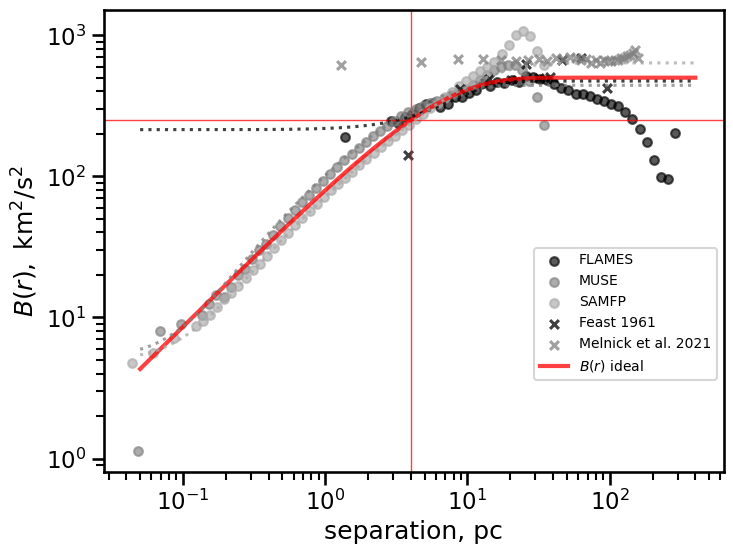

In [9]:
import bfunc
sns.set_context("talk")

rgrid = np.logspace(np.log10(0.05), np.log10(400), 500)

samples_to_plot = ["FLA", "MUSE", "SAMFP"]

colors = cycle(["black", "gray", "darkgray"])



fig, ax = plt.subplots(figsize=(8, 6))

# Existing datasets
for key in samples_to_plot:

    info = datasets[key]
    color = next(colors)

    ax.scatter(
        info["r"],
        info["B"],
        label=info["label"],
        alpha=0.65,
        color=color,
        marker="o",
        s=40,
    )

# Plot CSV datasets

# CSV files to include
csv_files = [
    "1961Fst30Dor_V2.csv",
    "2021Mk30DorII.csv",
#    "file3.csv",
]


csv_colors = cycle(["tab:blue", 
                    "tab:green", 
                    "tab:orange",
                    "tab:purple", 
                    "tab:brown"])

csv_labels = cycle (['Feast 1961',
                     'Melnick et al. 2021'
                    ])

sigma = [1,
         14.5**2]

for filename, factor in zip(csv_files, sigma):

    data = pd.read_csv(filename)

    ax.scatter(
        data["pc"],
        data["S"] * factor,
        label=next(csv_labels),
        color=next(colors),
        marker="x",
        s=40,
        alpha=0.75,
    )


r0=4
# Ideal model
ax.plot(
    rgrid,
    bfunc.bfunc00s(rgrid, r0, 250, 1.0),
    color="red",
    label=r"$B(r)$ ideal",
    alpha = 0.75,
    linewidth = 3.0,
)

# Horizontal line 
ax.axhline(y=250, color='red', linestyle='-', linewidth=1, alpha = 0.75)

# Vertical line 
ax.axvline(x=r0, color='red', linestyle='-', linewidth=1,alpha = 0.75)

# Model
ax.plot(
    rgrid,
    bfunc.bfunc03s(rgrid, 7.68, 133.05, 1.72, 0.2, 214.183),
    color="black",
#    label=r"$B(r)$ ideal",
    alpha = 0.75,
    linestyle = ':'
    #linewidth = 3.0,
)

# Model
ax.plot(
    rgrid,
    bfunc.bfunc03s(rgrid, 2.53, 225.71, 1.02, 0.085, 5.188),
    color="gray",
#    label=r"$B(r)$ ideal",
    alpha = 0.75,
    linestyle = ':'
    #linewidth = 3.0,
)

# Model
ax.plot(
    rgrid,
    bfunc.bfunc03s(rgrid, 5.97, 320.55, 0.98, 0.09, 4.91),
    color="darkgray",
#    label=r"$B(r)$ ideal",
    alpha = 0.75,
    linestyle = ':'
    #linewidth = 3.0,
)




ax.legend(bbox_to_anchor=(1, 0.5),     fontsize=10,
)

ax.set(
    xscale="log",
    yscale="log",
    xlabel="separation, pc",
    ylabel=r"$B(r),$ km$^2$/s$^2$",
)

plt.savefig("B_plot_30_Dor.pdf", dpi=300, bbox_inches="tight")
plt.show()

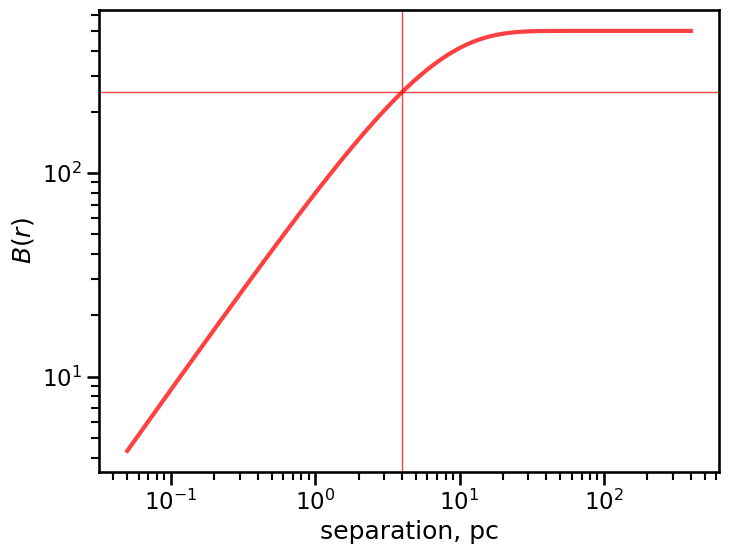

In [10]:
def bfunc00(r, r0, sig2, m):
    "Simple 3-parameter structure function"
    #C = np.exp(-np.log(2) * (r / r0) ** m)
    C = 2**(-(r/r0)**m)
    return 2.0 * sig2 * (1.0 - C)

rgrid = np.logspace(np.log10(0.05), np.log10(400), 500)


fig, ax = plt.subplots(figsize=(8, 6))

r0 = 4
sig2 = 250
m = 1.0

# Horizontal line 
ax.axhline(y=sig2, color='red', linestyle='-', linewidth=1, alpha = 0.75)

# Vertical line 
ax.axvline(x=r0, color='red', linestyle='-', linewidth=1,alpha = 0.75)

# Ideal model
ax.plot(
    rgrid,
    bfunc00(rgrid, r0, sig2, m),
    color="red",
    label=r"$B(r)$ ideal",
    alpha = 0.75,
    linewidth = 3.0,
)

ax.set(
    xscale="log",
    yscale="log",
    xlabel="separation, pc",
    ylabel=r"$B(r)$",
)

plt.show()

In [11]:
pd.read_csv('1961Fst30Dor.csv')

FileNotFoundError: [Errno 2] No such file or directory: '1961Fst30Dor.csv'